# F4 · Visualización y comunicación de resultados

**MCDI500 Programación para la Ciencia de Datos** · Magíster en Ciencia de Datos e Inteligencia Artificial · Universidad Andrés Bello
**Proyecto:** Análisis reproducible del Inventario Público de Glaciares de Chile 2022 · **Fase 4 — Semana 3 (proyecto final integrador)**
**Integrantes:** Francisco Correa Soto · Gustavo Aloy Angella · Roberto Gaubert Urbina · **Docente:** Dr. Omar Salinas Silva

Este notebook cierra el proyecto. **No vuelve a limpiar ni a transformar**: recibe lo que dejaron F2 y F3 en `data/processed/`, verifica que cumple lo prometido y responde con figuras la pregunta de investigación. Todo el código reutilizable vive en `src/` (`comunicacion.py` prepara las tablas y `figuras.py` las dibuja); aquí solo se ejecuta, se muestra y se interpreta.

| Fase | Notebook | Qué entrega a la siguiente |
|---|---|---|
| F1 | `F1/F1_Definicion.ipynb` | Problema, pregunta, objetivos, entorno y diccionario de variables |
| F2 | `F2/F2_Procesamiento.ipynb` | `glaciares_limpio.csv` (unidades físicas) y `glaciares_modelo.csv` (escalada y one-hot) |
| F3 | `F3/F3_NucleoAlgoritmico.ipynb` | Pipeline en clases y cinco tablas de concentración en `data/processed/` |
| **F4** | **este notebook** | Siete figuras, `docs/hallazgos_f4.csv` y `docs/metadatos_f4.json` para el informe y el video |

| Sección | Contenido | Apartado del entregable |
|---|---|---|
| 0–1 | Entorno, trazabilidad y objetivo de la fase | 4 · 5 · 6 |
| 2 | Artefactos de F3: contrato y verificación contra `data/raw` | 12 |
| 3 | Dos versiones del dato: matriz de modelo y copia interpretable | 20 |
| 4–6 | Una figura por objetivo en tres actos, con la descomposición de Theil, y figuras complementarias | 21 · 24 · 25 |
| 7 | Decisiones de escala: la figura que engaña | 21 |
| 8 | Eficiencia de la única operación nueva | 13 |
| 9 | Validación técnica | 12 · 23 |
| 10 | Persistencia: figuras, hallazgos y metadatos | 7 · 15 |
| 11 | Relato, discusión, limitaciones y conclusiones | 22 · 25 · 26 |

**Cómo ejecutarlo.** Después de F1, F2 y F3, con el kernel «Python (.venv grupo3)»: *Kernel → Restart Kernel and Run All Cells*. Si falta un artefacto de F3, la sección 2 se detiene con un mensaje que dice qué ejecutar; no se generan datos de reemplazo.

## 0. Entorno, módulos y trazabilidad

La raíz del repositorio se localiza desde la carpeta en que Jupyter abra el notebook (`F4/` o la raíz), igual que en F3. Se comprueba que el kernel corre dentro del entorno virtual y que las versiones instaladas son las declaradas en `requirements.txt`.

In [1]:
import importlib.metadata as metadata
import json
import sys
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = next(c for c in (Path.cwd(), *Path.cwd().parents) if (c / "src" / "utilidades.py").is_file())
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

import utilidades as utl           # F1–F2: rutas, huella, carga, pruebas
import concentracion as con        # F3: medidas de concentración
import medicion as me              # F3: medición de tiempo y memoria
import comunicacion as com         # F4: artefactos, contrato y tablas para graficar
import figuras as fg               # F4: una clase por figura (FiguraHallazgo)

np.random.seed(utl.SEMILLA)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
fg.aplicar_estilo()

declaradas = utl.leer_requirements(RAIZ / "requirements.txt")
print("Python:", sys.version.split()[0], "| entorno virtual:", "sí" if sys.prefix != sys.base_prefix else "NO")
for paquete in ("numpy", "pandas", "matplotlib", "seaborn"):
    instalada = metadata.version(paquete)
    aviso = "" if instalada == declaradas.get(paquete) else f"  ← requirements.txt declara {declaradas.get(paquete)}"
    print(f"{paquete}: {instalada}{aviso}")

Python: 3.14.10 | entorno virtual: sí
numpy: 2.5.4
pandas: 3.1.1
matplotlib: 3.11.2
seaborn: 0.13.2


In [2]:
SALIDAS_F4 = ["F4", "docs/hallazgos_f4.csv", "docs/metadatos_f4.json"]   # el notebook y lo que regenera
print("Repositorio:", utl.version_repositorio(RAIZ, excluir=SALIDAS_F4))
print("Identidad de Git:", utl.identidad_git(RAIZ))

RUTA_ORIGINAL = RAIZ / "data" / "raw" / utl.ARCHIVO_INVENTARIO
huella_inicial = utl.verificar_huella(RUTA_ORIGINAL)       # se detiene si data/raw cambió
print(f"data/raw verificado: SHA-256 {huella_inicial[:16]}…")

Repositorio: {'rama': 'f4-theil', 'commit': '5373480', 'cambios_sin_commit': True}
Identidad de Git: {'user.name': 'Francisco Correa', 'user.email': 'f.correasoto@uandresbello.edu', 'email_valido': True}
data/raw verificado: SHA-256 5691de5d7d7ffe2c…


## 1. Contexto y objetivo de la Fase 4

**Problemática.** Los glaciares son reservas hídricas estratégicas para Chile. La DGA publica el inventario oficial (26.180 glaciares, 45 variables) y sus totales, pero no un cálculo reproducible de cuán concentrada está la superficie glaciar. Saber si esa superficie depende de unos pocos glaciares, regiones y tipos importa para priorizar monitoreo: perder pocos glaciares grandes no equivale a perder muchos pequeños.

**Pregunta de investigación.** ¿Qué tan concentrada está la superficie glaciar en pocos glaciares y regiones, y cambia esa concentración según la clasificación del glaciar?

**Objetivo de esta fase (OE4).** Comunicar con tablas y visualizaciones reproducibles si la concentración cambia según la clasificación. F3 ya calculó las cifras; F4 las verifica, las convierte en figuras cuyo título dice el hallazgo y deja escrita la misma evidencia que usarán el informe y el video.

**Qué hace y qué no hace F4.**
- *Hace:* verifica el contrato con F3, construye la copia interpretable, grafica, mide la eficiencia de lo nuevo, valida y persiste.
- *Agrega una sola medida nueva:* la **descomposición del índice de Theil**, que separa la desigualdad en una parte entre grupos y otra dentro de ellos. El Gini no se descompone de forma exacta, así que sin Theil solo podríamos inferir cuánto pesa la clasificación; con él, lo medimos.
- *No hace:* limpiar, imputar ni recalcular el pipeline (eso es F2–F3); tampoco modela ni habla de cambios en el tiempo: el inventario es una fotografía de 2022 construida con imágenes de distintos años, y la concentración describe cómo se distribuye hoy la superficie inventariada, no su causa.

**Supuesto que condiciona la lectura** (F2 sección 2.3): el volumen **no es una medición**, se estimó desde el área (`VOL ≈ 0,0285 · ÁREA^1,357`). Por eso la superficie es la magnitud principal, y el volumen aparece una sola vez, para explicar por qué su concentración es mayor (figura 7).

---
## 2. Lo que entregaron F2 y F3

### 2.1 Carga de los artefactos

`com.cargar_artefactos` lee los siete archivos de `data/processed/`. `glaciares_limpio` se lee con `utl.cargar_limpio`, que restaura el orden de las ordinales (por ejemplo, las macrozonas de norte a sur) y los códigos como texto. Si falta un archivo, se detiene con `FileNotFoundError` y dice qué notebook ejecutar.

In [3]:
DIR_PROCESADO = RAIZ / "data" / "processed"
artefactos = com.cargar_artefactos(DIR_PROCESADO)
for nombre, tabla in artefactos.items():
    print(f"{nombre:<14} {com.ARTEFACTOS_F3[nombre]:<36} {tabla.shape[0]:>6} filas × {tabla.shape[1]:>2} columnas")

limpio, modelo = artefactos["limpio"], artefactos["modelo"]
magnitudes, lorenz = artefactos["magnitudes"], artefactos["lorenz"]

limpio         glaciares_limpio.csv                  26180 filas × 48 columnas
modelo         glaciares_modelo.csv                  26180 filas × 47 columnas
magnitudes     concentracion_magnitudes_f3.csv           3 filas ×  6 columnas
region         concentracion_region_f3.csv              16 filas ×  6 columnas
clasificacion  concentracion_clasificacion_f3.csv        5 filas ×  6 columnas
macrozona      concentracion_macrozona_f3.csv            4 filas ×  6 columnas
lorenz         lorenz_f3.csv                           201 filas ×  3 columnas


### 2.2 Verificar el contrato antes de graficar

F3 prometió unas cifras. Antes de usarlas se comprueba que son las que su propio código (`src/concentracion.py`) produce sobre `glaciares_limpio`: si alguien edita un CSV a mano o F3 se ejecuta con otra versión del dato, el contrato falla aquí y no en el informe.

In [4]:
contrato = com.verificar_contrato(artefactos)
display(contrato)
assert contrato["ok"].all(), "Los artefactos de F3 no coinciden con su recálculo: ejecutar F3 de nuevo"
print(f"Contrato con F3: {contrato['ok'].sum()}/{len(contrato)} controles cumplidos")

,control,ok,detalle
0,limpio y modelo tienen las mismas filas y el mismo orden de COD_GLA,True,26.180 glaciares
1,Sin nulos en las variables que se grafican,True,
2,Superficie sin valores negativos ni nulos,True,
3,concentracion_magnitudes_f3 = recálculo con concentracion.py,True,
4,concentracion_region_f3 = recálculo por REGION,True,16 grupos
5,concentracion_clasificacion_f3 = recálculo por CLASIFICA,True,5 grupos
6,concentracion_macrozona_f3 = recálculo por MZON_GLAC,True,4 grupos
7,lorenz_f3 = curva de Lorenz recalculada,True,201 puntos


Contrato con F3: 8/8 controles cumplidos


### 2.3 La verificación que no es circular: contra el archivo original

Comparar con el mismo código que produjo las tablas sería circular. Por eso se recalculan las cifras centrales **desde `data/raw`**, con pandas directo y con una fórmula del Gini distinta de la de F3: el área bajo la curva de Lorenz completa, $G = 1 - \frac{1}{n}\sum_{i=1}^{n}(L_i + L_{i-1})$, en vez de la fórmula por rangos de `IndiceGini`.

In [5]:
original = utl.cargar_inventario(RUTA_ORIGINAL)

def gini_trapecios(valores):
    # Fórmula independiente de la de F3: área bajo la curva de Lorenz con todos los puntos
    x = np.sort(np.asarray(valores, dtype=float))
    acumulada = np.concatenate([[0.0], np.cumsum(x) / x.sum()])
    return 1 - (acumulada[1:] + acumulada[:-1]).sum() / len(x)

f3 = magnitudes.set_index("magnitud").loc["AREA_KM2"]
pct_clase_raw = 100 * original.groupby("CLASIFICA")["AREA_KM2"].sum() / original["AREA_KM2"].sum()
pct_clase_f3 = artefactos["clasificacion"].set_index("CLASIFICA")["pct_superficie"]
pct_region_raw = 100 * original.groupby("REGION")["AREA_KM2"].sum() / original["AREA_KM2"].sum()
pct_region_f3 = artefactos["region"].set_index("REGION")["pct_superficie"]

independiente = pd.DataFrame([
    {"control": "Mismo número de glaciares", "data/raw": len(original), "F3": int(f3["glaciares"])},
    {"control": "Misma superficie total (km²)", "data/raw": original["AREA_KM2"].sum(), "F3": f3["total"]},
    {"control": "Mismo Gini de la superficie", "data/raw": gini_trapecios(original["AREA_KM2"]), "F3": f3["gini"]},
    {"control": "Mismo % de superficie por clasificación (máx. diferencia)",
     "data/raw": (pct_clase_raw - pct_clase_f3.reindex(pct_clase_raw.index)).abs().max(), "F3": 0.0},
    {"control": "Mismo % de superficie por región (máx. diferencia)",
     "data/raw": (pct_region_raw - pct_region_f3.reindex(pct_region_raw.index)).abs().max(), "F3": 0.0},
])
independiente["ok"] = np.isclose(independiente["data/raw"].astype(float), independiente["F3"].astype(float), atol=1e-9)
display(independiente)
assert independiente["ok"].all(), "Las cifras de F3 no se reproducen desde data/raw"

,control,data/raw,F3,ok
0,Mismo número de glaciares,2.618000e+04,26180.000000,True
1,Misma superficie total (km²),2.101234e+04,21012.341000,True
2,Mismo Gini de la superficie,9.373077e-01,0.937308,True
3,Mismo % de superficie por clasificación (máx. diferencia),3.552714e-15,0.000000,True
4,Mismo % de superficie por región (máx. diferencia),1.421085e-14,0.000000,True


**Resultado.** Las cifras de F3 se reproducen desde el archivo original con código independiente. F2 no eliminó ningún glaciar ni modificó `AREA_KM2`, así que la superficie es idéntica en `data/raw` y en `glaciares_limpio`; lo que F2 cambió (texto, tipos, faltantes encubiertos de `HMIN`, volúmenes redondeados a cero) no afecta las cifras que se comunican aquí.

---
## 3. Dos versiones del mismo dato: analizar no es comunicar

F2 dejó dos versiones del inventario, a propósito:

| Versión | Archivo | Para qué sirve | Por qué no sirve para la otra tarea |
|---|---|---|---|
| Matriz de modelo | `glaciares_modelo.csv` | Análisis y eventual modelado: todo numérico, `LOG_AREA` escalada con RobustScaler, categorías en one-hot | Un gráfico de `LOG_AREA_ESC` o de columnas 0/1 no tiene unidades ni nombres legibles |
| Copia interpretable | `glaciares_limpio.csv` | Comunicar: superficie en km², clasificación y región como texto, macrozonas en orden geográfico | Escalas y categorías de texto no entran directo a un modelo |

F4 grafica **solo** sobre la copia interpretable. Para demostrar que ambas son el mismo dato, `com.copia_interpretable` reconstruye la superficie y las categorías **desde la matriz de modelo**: revierte RobustScaler ($x = z \cdot \mathrm{IQR} + \mathrm{mediana}$), luego el logaritmo, y vuelve a juntar las columnas one-hot.

In [6]:
columnas_tipo = [c for c in modelo.columns if c.startswith(com.PREFIJO_TIPO)]
print("Así se ve la matriz de modelo (primeras filas):")
display(modelo[["COD_GLA", "LOG_AREA_ESC", *columnas_tipo]].head(3))

reconstruida = com.copia_interpretable(modelo, limpio["LOG_AREA"])
print("Y así la copia reconstruida desde ella:")
display(reconstruida.head(3))

dos_versiones = {
    "Clasificación reconstruida = glaciares_limpio": (reconstruida["CLASIFICA"].to_numpy() == limpio["CLASIFICA"].astype(str).to_numpy()).all(),
    "Región reconstruida = glaciares_limpio": (reconstruida["REGION"].to_numpy() == limpio["REGION"].astype(str).to_numpy()).all(),
    "Superficie reconstruida = glaciares_limpio (km²)": np.allclose(reconstruida["AREA_KM2"], limpio["AREA_KM2"], rtol=1e-9, atol=1e-8),
    "Superficie reconstruida = data/raw (valores ordenados)": np.allclose(np.sort(reconstruida["AREA_KM2"]), np.sort(original["AREA_KM2"]), rtol=1e-9, atol=1e-8),
}
for control, ok in dos_versiones.items():
    print(f"[{'OK' if ok else 'FALLA'}] {control}")
assert all(dos_versiones.values())
print(f"Máxima diferencia de superficie: {np.abs(reconstruida['AREA_KM2'] - limpio['AREA_KM2']).max():.1e} km² (redondeo del CSV)")

Así se ve la matriz de modelo (primeras filas):


,COD_GLA,LOG_AREA_ESC,OH_TIPO_GLACIAR DE MONTAÑA,OH_TIPO_GLACIAR DE VALLE,OH_TIPO_GLACIAR EFLUENTE,OH_TIPO_GLACIAR ROCOSO,OH_TIPO_GLACIARETE
0,CL101010001@,1.325038,1,0,0,0,0
1,CL101001023@,0.984808,1,0,0,0,0
2,CL101021004@,0.572767,0,0,0,0,1


Y así la copia reconstruida desde ella:


,COD_GLA,CLASIFICA,REGION,AREA_KM2
0,CL101010001@,GLACIAR DE MONTAÑA,ARICA Y PARINACOTA,1.168
1,CL101001023@,GLACIAR DE MONTAÑA,ARICA Y PARINACOTA,0.478
2,CL101021004@,GLACIARETE,ARICA Y PARINACOTA,0.162


[OK] Clasificación reconstruida = glaciares_limpio
[OK] Región reconstruida = glaciares_limpio
[OK] Superficie reconstruida = glaciares_limpio (km²)
[OK] Superficie reconstruida = data/raw (valores ordenados)
Máxima diferencia de superficie: 3.3e-09 km² (redondeo del CSV)


La figura siguiente muestra por qué no se grafica la matriz: la misma variable, en la matriz escalada, se lee en «desviaciones robustas» sin unidad; en la copia interpretable se lee en km².

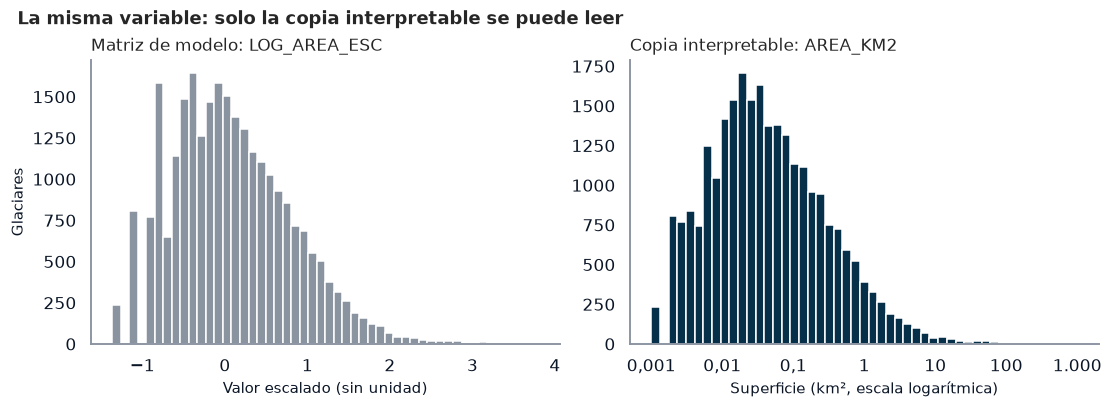

In [7]:
figura_versiones, (izq, der) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
izq.hist(modelo["LOG_AREA_ESC"], bins=50, color=fg.GRIS)
izq.set(title="Matriz de modelo: LOG_AREA_ESC", xlabel="Valor escalado (sin unidad)", ylabel="Glaciares")
der.hist(limpio["AREA_KM2"], bins=np.logspace(-3, 3, 50), color=fg.AZUL)
der.set_xscale("log")
fg.formato_eje_km2(der.xaxis)
der.set(title="Copia interpretable: AREA_KM2", xlabel="Superficie (km², escala logarítmica)")
figura_versiones.suptitle("La misma variable: solo la copia interpretable se puede leer", x=0.01, ha="left",
                          fontweight="bold", fontsize=12)
plt.show()

---
## 4. Una figura por objetivo

Un gráfico responde una pregunta. Antes de dibujar se declara qué objetivo responde cada figura; si un objetivo quedara sin figura, el trabajo estaría incompleto. Cada figura es un objeto de una clase hija de `fg.FiguraHallazgo`: todas se construyen, guardan y registran con las mismas llamadas (polimorfismo), y su título se arma con las cifras de su propia tabla, de modo que figura, `hallazgos_f4.csv` e informe no pueden contradecirse.

Las tres principales siguen el hilo **contexto → contraste → resolución** y van al cuerpo del informe; las cuatro complementarias van a anexos y al video. El volumen va al final, como magnitud secundaria.

In [8]:
figuras = [
    fg.FiguraLorenz(lorenz, magnitudes),              # acto 1 · contexto
    fg.FiguraComposicion(limpio),                     # acto 2 · contraste
    fg.FiguraTheil(limpio),                           # acto 3 · resolución: descomposición de Theil
    fg.FiguraTamanoPorTipo(limpio, magnitudes),       # complementaria · por qué difieren los tipos
    fg.FiguraRegiones(limpio),                        # complementaria · geografía
    fg.FiguraTipoPorMacrozona(limpio),                # complementaria · control por una tercera variable
    fg.FiguraVolumenDerivado(limpio, magnitudes),     # complementaria · magnitud secundaria
]
vinculacion = pd.DataFrame([{k: f.registro()[k] for k in ("figura", "rol", "objetivo", "grafico")} for f in figuras])
vinculacion

,figura,rol,objetivo,grafico
0,fig1_lorenz_superficie,principal,OE3 · ¿Qué tan concentrada está la superficie glaciar en pocos glaciares?,Líneas (curva de Lorenz) con detalle del 10 % mayor
1,fig2_composicion_clasificacion,principal,OE4 · ¿Cambia la concentración según la clasificación del glaciar?,Barras pareadas: % de los glaciares y % de la superficie por clasificación
2,fig3_descomposicion_theil,principal,OE4 · ¿Qué parte de la concentración se asocia a la clasificación y cuál a la región?,Barras apiladas al 100 %: desigualdad entre y dentro de los grupos (descomposición de ...
3,fig4_tamano_por_clasificacion,complementaria,OE4 · ¿Por qué cambia la concentración según la clasificación?,"Caja con puntos superpuestos, eje logarítmico, con el Gini de cada tipo"
4,fig5_superficie_por_region,complementaria,OE3 · ¿Qué tan concentrada está la superficie glaciar en pocas regiones?,"Barras horizontales ordenadas, con las dos mayores destacadas"
5,fig6_tipo_por_macrozona,complementaria,OE4 · ¿El efecto de la clasificación se mantiene al separar por macrozona?,Mapa de calor de una tabla cruzada (porcentaje de la fila)
6,fig7_volumen_derivado,complementaria,OE3 · ¿Por qué el volumen está más concentrado que la superficie?,Dispersión log-log con recta de igualdad


---
## 5. Las figuras principales: tres actos

### Figura 1 · Contexto: la superficie está extremadamente concentrada

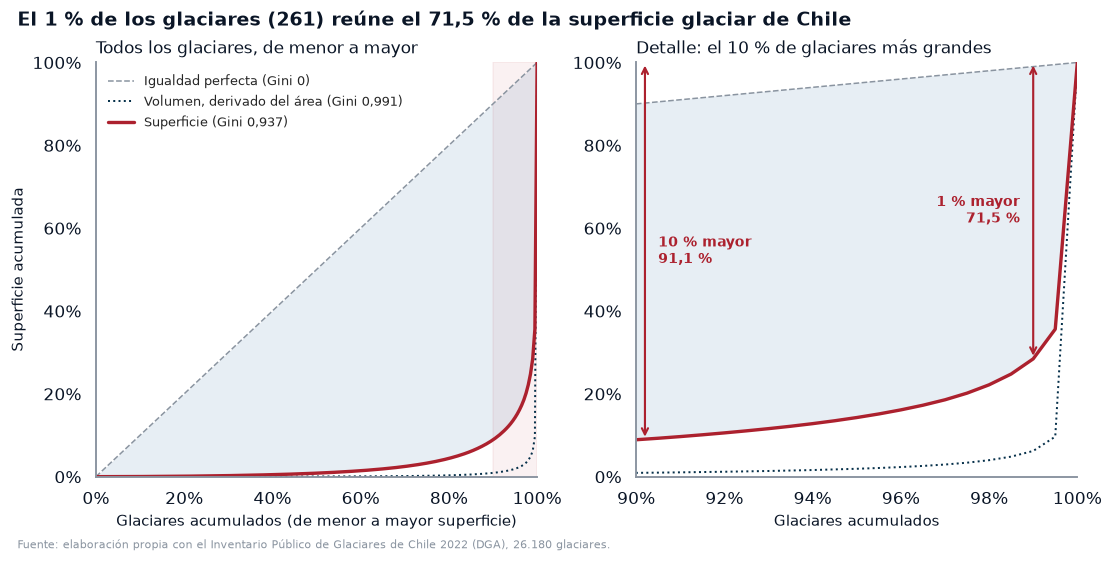

1 % mayor: 71,5 %; 10 % mayor: 91,1 %; Gini superficie 0,937 (volumen derivado 0,991) sobre 21.012 km²


In [9]:
figuras[0].construir()
plt.show()
print(figuras[0].evidencia())

**Resultado.** El 1 % de los glaciares (261) reúne el 71,5 % de los 21.012 km² de superficie, y el 10 % reúne el 91,1 % (Gini 0,937). El panel derecho amplía el tramo donde ocurre todo: la curva casi no se separa de cero hasta el último 10 % de los glaciares.

**Interpretación.** El 90 % de los glaciares —más de 23.500— aporta menos de una décima parte de la superficie inventariada. La curva punteada del volumen está aún más pegada al eje; la figura 7 explica por qué.

**Límite.** El Gini y la curva tratan cada polígono del inventario como una unidad. Un glaciar efluente forma parte de un campo de hielo mayor, así que la concentración depende de cómo la DGA delimitó cada glaciar.

### Figura 2 · Contraste: la concentración cambia según la clasificación

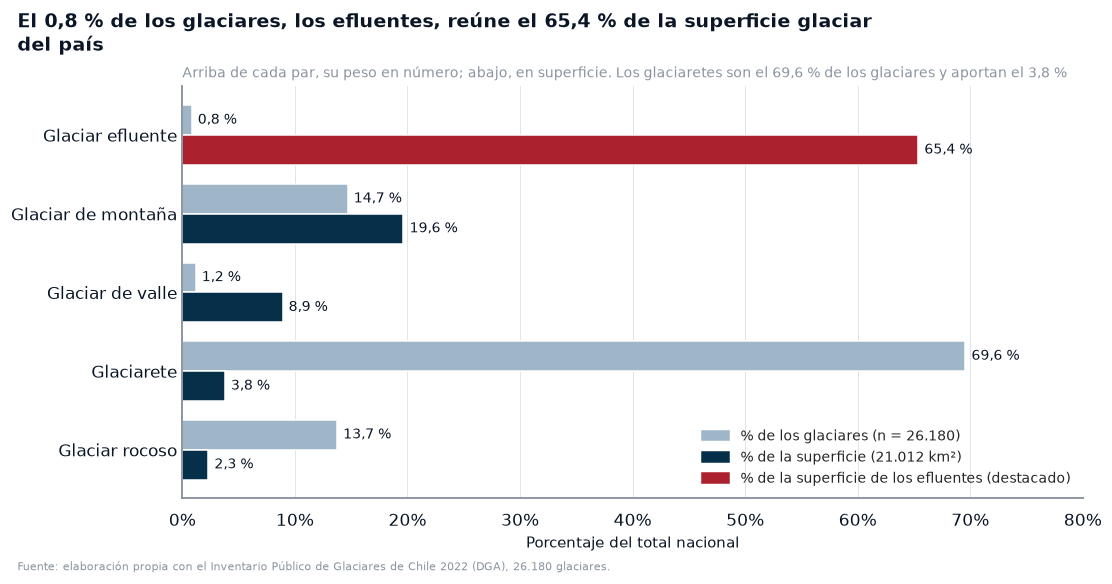

,glaciares,total,pct_glaciares,pct_magnitud,razon,pct_acumulado
CLASIFICA,,,,,,
GLACIAR EFLUENTE,217,13737.60,0.83,65.38,78.88,65.38
GLACIAR DE MONTAÑA,3844,4128.05,14.68,19.65,1.34,85.02
GLACIAR DE VALLE,310,1870.42,1.18,8.90,7.52,93.93
GLACIARETE,18211,792.20,69.56,3.77,0.05,97.70
GLACIAR ROCOSO,3598,484.07,13.74,2.30,0.17,100.00


In [10]:
figuras[1].construir()
plt.show()
display(figuras[1].tabla.round(2))

**Resultado.** Los 217 glaciares efluentes son el 0,8 % de los glaciares y reúnen el 65,4 % de la superficie (78,9 veces su peso en número). En el otro extremo, los 18.211 glaciaretes son el 69,6 % de los glaciares y aportan el 3,8 %.

**Interpretación.** Responde la segunda parte de la pregunta: la concentración **cambia según la clasificación**. Las barras pareadas ponen lado a lado, para cada tipo, su peso en número y su peso en superficie; la distancia entre las dos barras de cada par es el hallazgo.

**Límite.** La clasificación es la que asignó la DGA al digitalizar; no se revisó su consistencia entre fuentes de imagen ni entre años de digitalización.

### Figura 3 · Resolución: cuánto de la desigualdad se asocia a la clasificación y cuánto a la región

El Gini dentro de cada clasificación (0,50 a 0,71) es menor que el total (0,937), pero eso solo **sugiere** que el tipo pesa: el Gini no se descompone de forma exacta entre grupos. El **índice de Theil** sí (Theil, 1967; Shorrocks, 1980):

$$T = \underbrace{\sum_g s_g \ln\frac{\mu_g}{\mu}}_{\text{entre grupos}} + \underbrace{\sum_g s_g\, T_g}_{\text{dentro de los grupos}}$$

donde $s_g$ es la fracción de la superficie que aporta el grupo $g$, $\mu_g$ su superficie media y $T_g$ su Theil interno. La parte «entre» es la desigualdad que quedaría si cada glaciar tuviera la superficie media de su grupo. `con.IndiceTheil` y `con.descomponer_theil` lo implementan, y `pruebas_concentracion.py` comprueba que las dos partes suman el total.

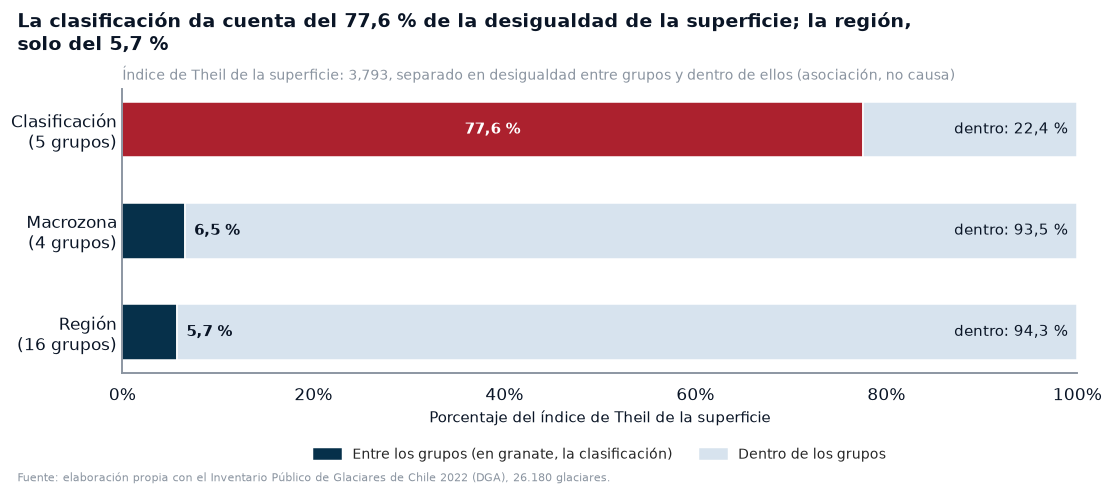

,grupos,theil_total,entre,dentro,pct_entre,pct_dentro
agrupacion,,,,,,
Clasificación,5,3.793,2.941,0.851,77.554,22.446
Macrozona,4,3.793,0.247,3.545,6.520,93.480
Región,16,3.793,0.217,3.576,5.713,94.287


Theil de la superficie: 3.793 (máximo posible ln(n) = 10.17)


In [11]:
figuras[2].construir()
plt.show()
theil = figuras[2].tabla
display(theil[["grupos", "theil_total", "entre", "dentro", "pct_entre", "pct_dentro"]].round(3))
assert np.allclose(theil["entre"] + theil["dentro"], theil["theil_total"]), "La descomposición no suma el total"
print(f"Theil de la superficie: {theil['theil_total'].iloc[0]:.3f} (máximo posible ln(n) = {np.log(len(limpio)):.2f})")

**Resultado.** De la desigualdad de la superficie (Theil 3,793), la diferencia **entre clasificaciones** da cuenta del **77,6 %**; la diferencia entre macrozonas, del 6,5 %, y entre regiones, solo del **5,7 %**.

**Interpretación.** Esto convierte la inferencia de F3 en un resultado medido: la concentración se asocia sobre todo al **tipo** de glaciar. Y aclara una lectura que la figura 5 podría inducir: que Magallanes y Aysén reúnan el 91,1 % de la superficie **no** significa que la región explique la desigualdad, porque dentro de esas regiones conviven efluentes de cientos de km² con miles de glaciares pequeños (Aysén tiene 10.301 glaciares). La desigualdad se concentra dentro de las regiones, no entre ellas.

**Límite.** Es una descomposición de la desigualdad, no un modelo causal: «da cuenta de» significa que, si cada glaciar tuviera la superficie media de su tipo, se conservaría el 77,6 % del índice. El resultado depende de las cinco clases de la DGA, y clasificación y latitud están entrelazadas (figura 6).

---
## 6. Figuras complementarias

### Figura 4 · Por qué difieren los tipos: cada uno ocupa su propio rango de tamaño

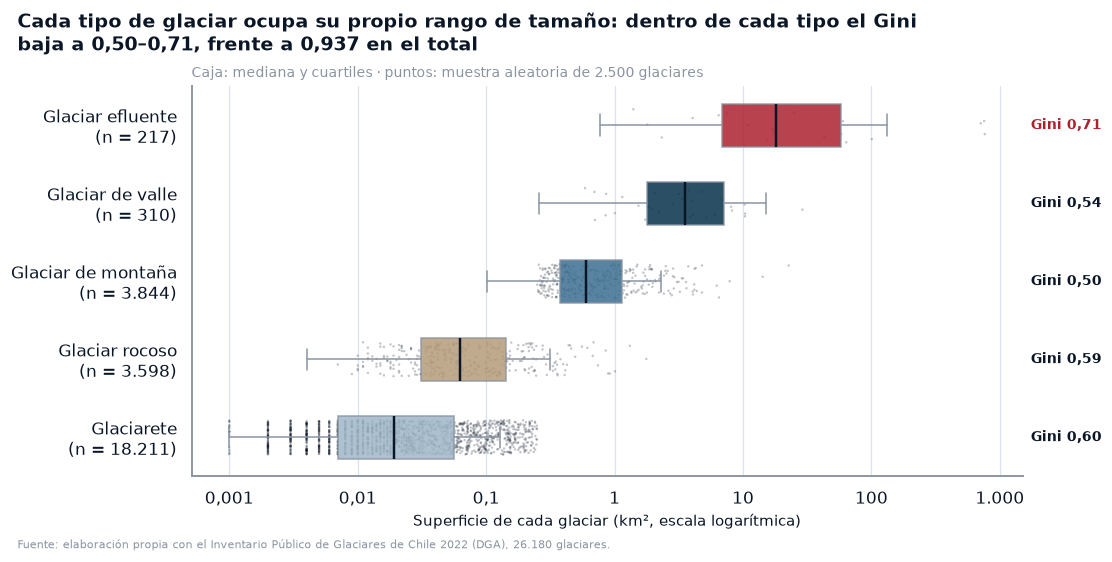

,glaciares,gini,mediana_km2
CLASIFICA,,,
GLACIAR EFLUENTE,217,0.709,18.217
GLACIAR DE VALLE,310,0.535,3.510
GLACIAR DE MONTAÑA,3844,0.499,0.598
GLACIAR ROCOSO,3598,0.594,0.063
GLACIARETE,18211,0.602,0.019


In [12]:
figuras[3].construir()
plt.show()
display(figuras[3].tabla.round(3))

**Lectura.** Las medianas van de 0,019 km² (glaciaretes) a 18,2 km² (efluentes): casi tres órdenes de magnitud. Dentro de cada tipo el Gini es moderado (0,50 a 0,71), coherente con la parte «dentro» de Theil (22,4 %). La escala logarítmica es necesaria: en escala lineal todas las cajas salvo la de los efluentes quedarían aplastadas contra el cero (sección 7). Los puntos son una muestra aleatoria de 2.500 glaciares (semilla 42), solo para mostrar la densidad.

### Figura 5 · Dos regiones reúnen casi toda la superficie

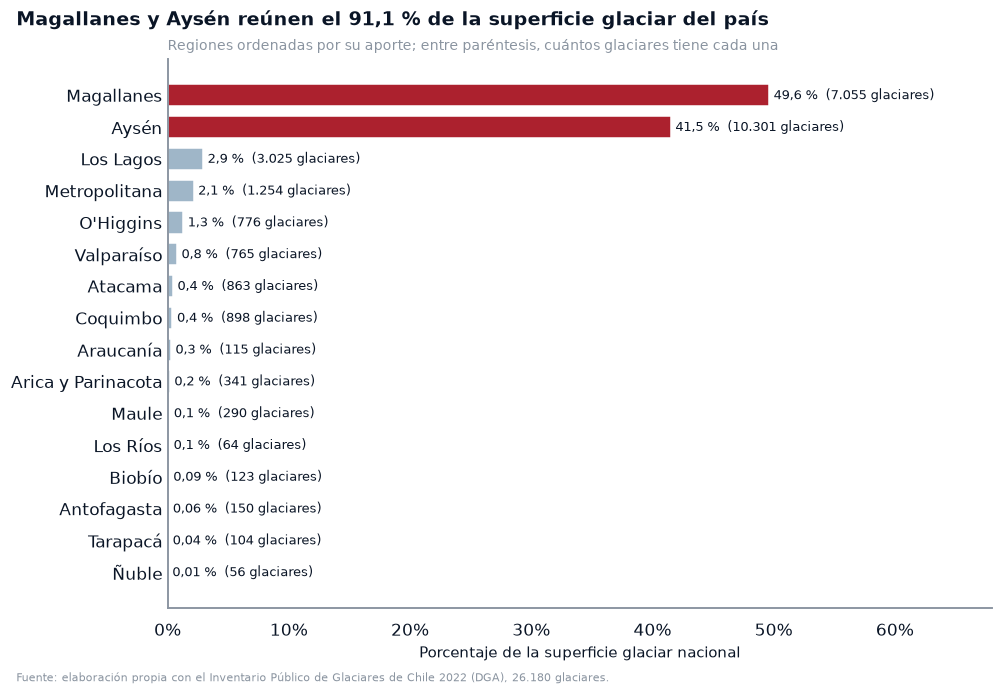

In [13]:
figuras[4].construir()
plt.show()

**Lectura.** Magallanes (49,6 %) y Aysén (41,5 %) reúnen el 91,1 % de la superficie con el 66,3 % de los glaciares (17.356). Las otras 14 regiones suman el 8,9 %. Es una concentración **geográfica** de la superficie; como muestra la figura 3, la región da cuenta de solo el 5,7 % de la **desigualdad** entre glaciares. Barras horizontales ordenadas porque hay 16 categorías con nombres largos; el eje parte en cero porque la longitud codifica la magnitud.

### Figura 6 · Control por una tercera variable: la geografía

Clasificación y latitud podrían estar entrelazadas. Se separa la superficie de cada macrozona por tipo de glaciar y se repite la medición sin los efluentes.

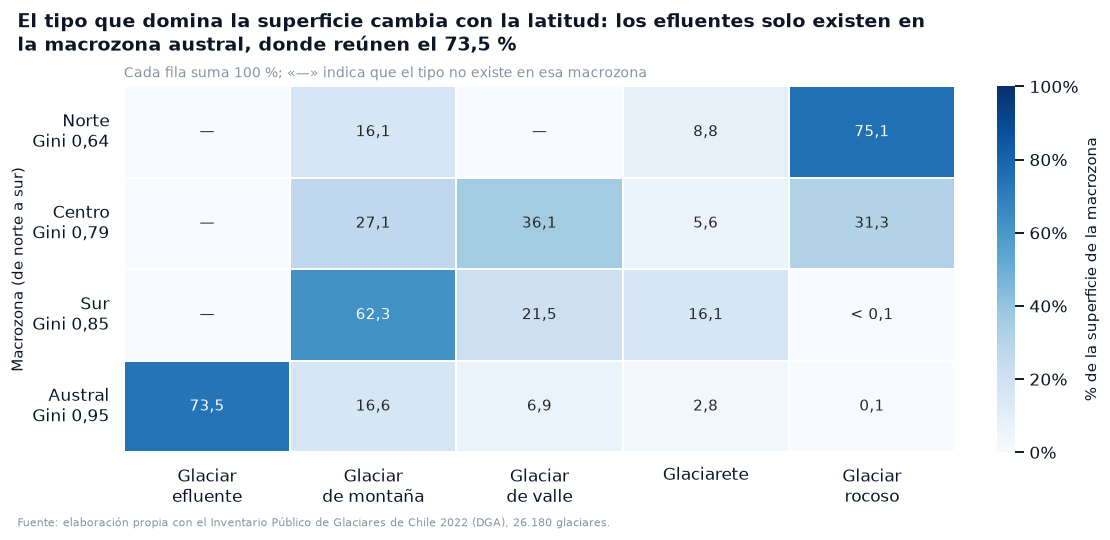

CLASIFICA,GLACIAR EFLUENTE,GLACIAR DE MONTAÑA,GLACIAR DE VALLE,GLACIARETE,GLACIAR ROCOSO
MZON_GLAC,,,,,
MACROZONA NORTE,0.0,16.1,0.0,8.8,75.1
MACROZONA CENTRO,0.0,27.1,36.1,5.6,31.3
MACROZONA SUR,0.0,62.3,21.5,16.1,0.0
MACROZONA AUSTRAL,73.5,16.6,6.9,2.8,0.1


,conjunto,glaciares,total,pct_1%_mayores,pct_10%_mayores,gini
0,Todos los glaciares,26180,21012.341,71.525,91.096,0.937
1,Sin glaciares efluentes,25963,7274.741,32.852,75.778,0.837
2,Fuera de campos de hielo,25457,6449.241,33.268,74.976,0.832


In [14]:
figuras[5].construir()
plt.show()
display(figuras[5].tabla.round(1))

sin_efluentes = limpio.loc[limpio["CLASIFICA"] != "GLACIAR EFLUENTE", "AREA_KM2"]
fuera_campo = limpio.loc[limpio["EN_CAMPO_HIELO"] == 0, "AREA_KM2"]
control = pd.DataFrame([
    {"conjunto": "Todos los glaciares", "glaciares": len(limpio), **con.AnalisisConcentracion(limpio, "AREA_KM2", con.medidas_proyecto()).resumen()},
    {"conjunto": "Sin glaciares efluentes", "glaciares": len(sin_efluentes),
     **con.AnalisisConcentracion(sin_efluentes.to_frame(), "AREA_KM2", con.medidas_proyecto()).resumen()},
    {"conjunto": "Fuera de campos de hielo", "glaciares": len(fuera_campo),
     **con.AnalisisConcentracion(fuera_campo.to_frame(), "AREA_KM2", con.medidas_proyecto()).resumen()},
]).drop(columns=["magnitud"])
display(control.round(3))

**Lectura.** El tipo dominante cambia de norte a sur: glaciares rocosos en el norte (75,1 %), de valle en el centro (36,1 %), de montaña en el sur (62,3 %) y efluentes en la macrozona austral (73,5 %), el único lugar donde existen, porque descienden de los Campos de Hielo Norte y Sur.

**¿Desaparece la concentración si se quitan los efluentes?** No. Sin ellos el Gini baja de 0,937 a 0,837 y el 1 % mayor pasa de reunir el 71,5 % al 32,9 %; fuera de los campos de hielo el resultado es parecido (Gini 0,832). La concentración **se reduce pero persiste**. Por eso el informe dice que la concentración **se asocia** al tipo de glaciar, no que el tipo la cause.

### Figura 7 · Magnitud secundaria: por qué el volumen está más concentrado

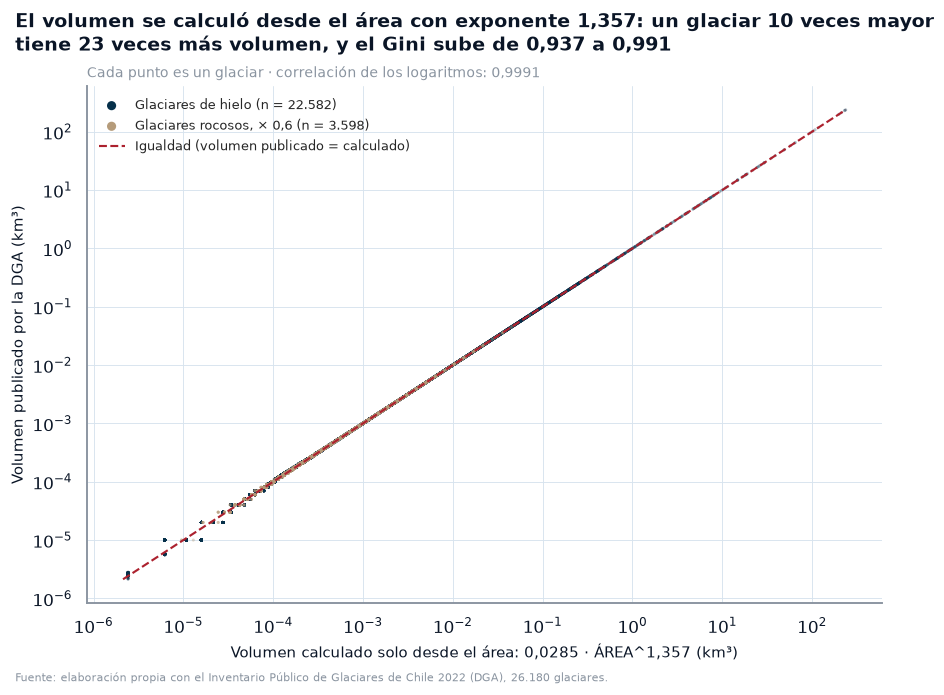

Gini 0,937 (superficie) → 0,991 (volumen); 1 % mayor 71,5 % → 93,8 %; correlación (log10) con el volumen calculado solo desde el área 0,9991


In [15]:
figuras[6].construir()
plt.show()
print(figuras[6].evidencia())

**Lectura.** El volumen no se midió: la DGA lo calculó desde el área con $V \approx 0{,}0285 \cdot A^{1{,}357}$, y un volumen calculado solo así cae sobre el publicado (correlación de los logaritmos 0,999). Como el exponente es mayor que 1, la fórmula **amplifica** las diferencias de tamaño: un glaciar 10 veces mayor tiene $10^{1{,}357} \approx 23$ veces más volumen. Por eso el Gini sube de 0,937 a 0,991 y el 1 % mayor pasa de reunir el 71,5 % de la superficie al 93,8 % del volumen. No es un segundo hallazgo, sino la misma concentración de la superficie vista a través de una fórmula. La dispersión en los valores más pequeños viene del redondeo del volumen publicado a cinco decimales.

---
## 7. Decisiones de escala: la figura que engaña

El descriptor evalúa que las escalas sean adecuadas. La superficie tiene asimetría 43 (F2): con un eje lineal, el histograma pone casi todos los glaciares en la primera barra y oculta la distribución. No es una mentira por recorte de eje, pero sí una figura que no comunica nada.

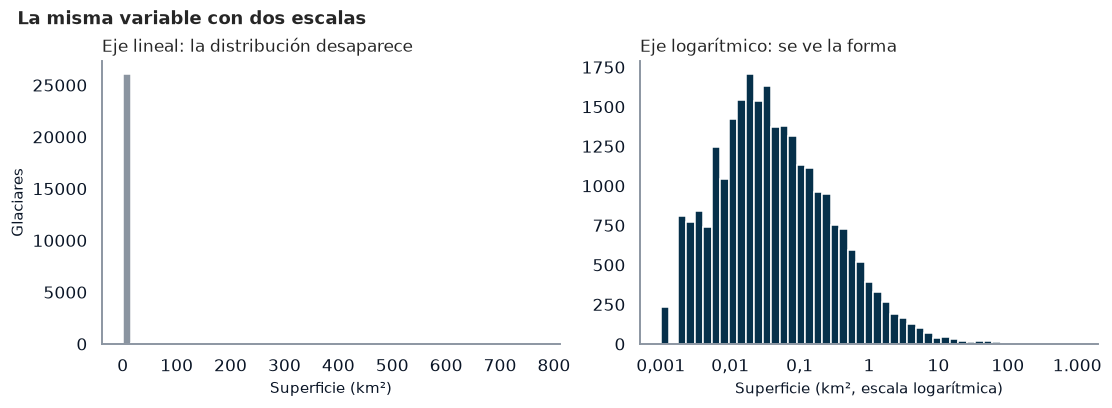

Con eje lineal, la primera barra (0 a 15.5 km²) contiene el 99,4 % de los glaciares.


In [16]:
figura_escala, (lineal, logaritmica) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
conteos, bordes, _ = lineal.hist(limpio["AREA_KM2"], bins=50, color=fg.GRIS)
lineal.set(title="Eje lineal: la distribución desaparece", xlabel="Superficie (km²)", ylabel="Glaciares")
logaritmica.hist(limpio["AREA_KM2"], bins=np.logspace(-3, 3, 50), color=fg.AZUL)
logaritmica.set_xscale("log")
fg.formato_eje_km2(logaritmica.xaxis)
logaritmica.set(title="Eje logarítmico: se ve la forma", xlabel="Superficie (km², escala logarítmica)")
figura_escala.suptitle("La misma variable con dos escalas", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.show()
print(f"Con eje lineal, la primera barra (0 a {bordes[1]:.1f} km²) contiene el {com.pct(100 * conteos[0] / len(limpio))} "
      "de los glaciares.")

**Reglas que aplicamos en las siete figuras.**
- **Barras (figuras 2, 3 y 5): eje desde cero**, porque la longitud codifica la magnitud; recortarlo multiplicaría visualmente las diferencias.
- **Tamaños y volúmenes (figuras 4 y 7): eje logarítmico**, declarado en la etiqueta del eje, porque los valores abarcan seis órdenes de magnitud.
- **Proporciones (figuras 1, 2, 3, 5 y 6): en porcentaje**, con coma decimal y la base (n o km²) a la vista.
- **Color con función:** granate solo en lo que sostiene el hallazgo; cada clasificación tiene el mismo color en todas las figuras.
- **Sin gráficos circulares ni 3D:** hay cinco tipos y dieciséis regiones; el ojo compara longitudes mejor que ángulos.

---
## 8. Eficiencia: la única operación nueva

F4 casi no agrega cálculo. Su operación propia es la **participación de cada grupo** en la superficie, que alimenta las figuras 2, 4 y 6. Se comparan tres implementaciones con el mismo método formal de F3 (`me.comparar`: equivalencia verificada antes de medir, mínimo de 5 repeticiones con `timeit` y memoria pico con `tracemalloc`) sobre tamaños crecientes, remuestreando glaciares con reemplazo (semilla 42) para llegar más allá de los 26.180 reales.

| Implementación | Idea | Complejidad teórica |
|---|---|---|
| `bucle` | Diccionario recorrido fila a fila en Python | Tiempo O(n), memoria O(k) |
| `pandas` | `groupby(...).sum()` (la que usa `com.composicion`) | Tiempo O(n), memoria O(n) |
| `bincount` | `np.unique` + `np.bincount` sobre códigos enteros | Tiempo O(n log n) por `unique`, memoria O(n) |

In [17]:
generador = np.random.default_rng(utl.SEMILLA)
grupos_base = limpio["CLASIFICA"].astype(str).to_numpy()
areas_base = limpio["AREA_KM2"].to_numpy()

def muestra(n):
    indices = generador.choice(len(limpio), size=n, replace=True)
    return grupos_base[indices], areas_base[indices]

entradas = {n: muestra(n) for n in (1_000, 10_000, 26_180, 100_000, 300_000)}
implementaciones = {
    "bucle": lambda e: com.participacion_por_grupo_bucle(*e),
    "pandas": lambda e: com.participacion_por_grupo_pandas(*e),
    "bincount": lambda e: com.participacion_por_grupo_bincount(*e),
}

def mismas_participaciones(a, b):
    return list(a.index) == list(b.index) and np.allclose(a.to_numpy(), b.to_numpy(), atol=1e-9)

eficiencia = me.comparar(implementaciones, entradas, repeticiones=5, equivalentes=mismas_participaciones)
display(eficiencia.pivot(index="n", columns="implementacion", values="ms").round(2)
        .rename(columns=lambda c: f"{c} (ms)"))
display(eficiencia.pivot(index="n", columns="implementacion", values="memoria_mb").round(2)
        .rename(columns=lambda c: f"{c} (MB)"))
display(me.exponente_empirico(eficiencia))

implementacion,bincount (ms),bucle (ms),pandas (ms)
n,,,
1000,0.25,0.25,0.34
10000,1.94,1.00,0.69
26180,5.33,2.38,1.25
100000,22.64,8.57,3.95
300000,77.90,26.29,14.82


implementacion,bincount (MB),bucle (MB),pandas (MB)
n,,,
1000,0.04,0.01,0.07
10000,0.39,0.01,0.61
26180,1.02,0.01,2.11
100000,3.91,0.01,5.31
300000,11.73,0.01,18.93


,implementacion,exponente_tiempo
0,bucle,0.82
1,pandas,0.65
2,bincount,1.01


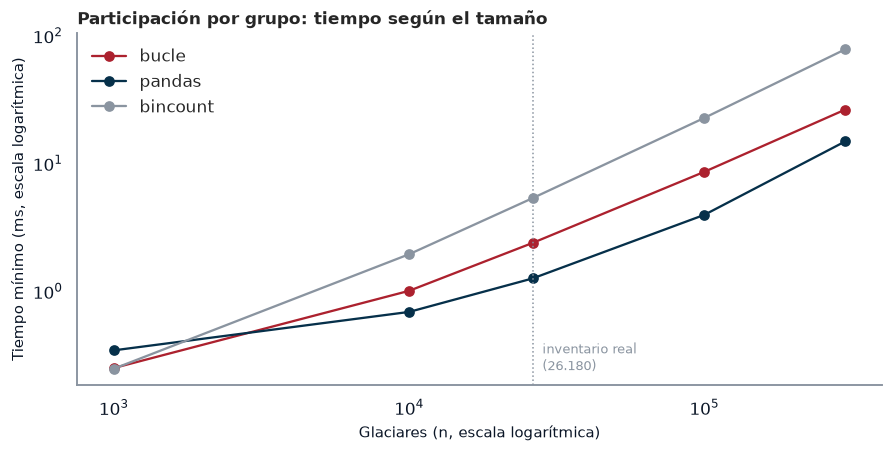

Con los 26.180 glaciares: bucle 2.4 ms, pandas 1.3 ms, bincount 5.3 ms → el bucle es 2 veces más lento que pandas.


In [18]:
figura_eficiencia, eje = plt.subplots(figsize=(8, 4), layout="constrained")
colores = {"bucle": fg.GRANATE, "pandas": fg.AZUL, "bincount": fg.GRIS}
for nombre, grupo in eficiencia.groupby("implementacion", sort=False):
    eje.plot(grupo["n"], grupo["ms"], marker="o", color=colores[nombre], label=nombre)
eje.set_xscale("log")
eje.set_yscale("log")
eje.axvline(26_180, color=fg.GRIS, ls=":", lw=1)
eje.text(26_180 * 1.08, eje.get_ylim()[0] * 1.3, "inventario real\n(26.180)", fontsize=8.5, color=fg.GRIS)
eje.set(xlabel="Glaciares (n, escala logarítmica)", ylabel="Tiempo mínimo (ms, escala logarítmica)")
eje.legend()
eje.set_title("Participación por grupo: tiempo según el tamaño", fontweight="bold")
plt.show()

en_real = eficiencia[eficiencia["n"] == 26_180].set_index("implementacion")
print(f"Con los 26.180 glaciares: bucle {en_real.loc['bucle', 'ms']:.1f} ms, pandas {en_real.loc['pandas', 'ms']:.1f} ms, "
      f"bincount {en_real.loc['bincount', 'ms']:.1f} ms → el bucle es "
      f"{en_real.loc['bucle', 'ms'] / en_real.loc['pandas', 'ms']:.0f} veces más lento que pandas.")

**Interpretación** (los tiempos cambian entre equipos; lo que se interpreta es su forma).

- **Las tres dan el mismo resultado**: `me.comparar` lo verifica antes de medir; si no coincidieran, se detendría.
- **Con el inventario real, `pandas` es la más rápida**, y su ventaja crece con n. En el tamaño más chico (1.000) el bucle la iguala o la supera: `groupby` tiene un costo fijo (crear la Series y el índice de grupos) que pesa más que el ahorro cuando hay pocos datos. Por eso los exponentes empíricos de `bucle` y `pandas` salen menores que 1: entre 1.000 y 26.180 domina el costo fijo; entre 100.000 y 300.000 el tiempo ya crece casi en proporción a n.
- **`bincount` es la más lenta y la única con exponente ≈ 1 o mayor**: `np.unique` ordena las etiquetas de texto, y ordenar es O(n log n) con comparaciones de cadenas costosas. La teoría lo anticipaba en la tabla de arriba.
- **Memoria: el bucle no crece** (O(k), un acumulador por cada uno de los 5 tipos), mientras pandas y NumPy crean arreglos intermedios de tamaño n (O(n)). Con 26.180 glaciares son unos pocos MB, irrelevantes.

**Decisión.** Se mantiene `groupby` de pandas en `com.composicion`: es la más rápida en el tamaño real, conserva las categorías y el orden de `glaciares_limpio` y se lee en una línea. El bucle sería la elección correcta solo si el inventario no cupiera en memoria y hubiera que leerlo por partes, porque su memoria no depende de n. `bincount` se descarta: es más lenta y obliga a reconstruir las etiquetas.

---
## 9. Validación técnica

Tres escenarios, como pide el descriptor —casos normales, límite y excepciones—, más cifras de control que fijan los números del informe. Las pruebas viven en `src/` y también se ejecutan desde la terminal (`python src/pruebas_comunicacion.py`, `python src/pruebas_figuras.py`). Se vuelven a ejecutar las de concentración de F3 porque F4 depende de ellas.

In [19]:
import pruebas_comunicacion
import pruebas_figuras
import pruebas_concentracion

baterias = {"comunicacion (F4)": pruebas_comunicacion.pruebas(),
            "figuras (F4)": pruebas_figuras.pruebas(),
            "concentracion (F3)": pruebas_concentracion.pruebas()}
resultados = pd.concat([utl.ejecutar_pruebas(pruebas).assign(modulo=modulo) for modulo, pruebas in baterias.items()],
                       ignore_index=True)
plt.close("all")                                   # las pruebas construyen figuras: no se muestran
resumen_pruebas = (resultados.assign(ok=resultados["resultado"].eq("OK"))
                   .pivot_table(index="modulo", columns="tipo", values="ok", aggfunc="sum", fill_value=0))
resumen_pruebas["total"] = resumen_pruebas.sum(axis=1)
display(resumen_pruebas)
fallidas = resultados[~resultados["resultado"].eq("OK")]
assert fallidas.empty, f"Pruebas fallidas:\n{fallidas.to_string()}"
print(f"OK: {len(resultados)}/{len(resultados)} pruebas.")

tipo,control,excepción,límite,normal,total
modulo,,,,,
comunicacion (F4),5,6,5,8,24
concentracion (F3),5,12,8,7,32
figuras (F4),7,3,4,6,20


OK: 76/76 pruebas.


In [20]:
# Detalle de las pruebas de F4, que es la evidencia que se cita en el informe (apartado 12)
resultados[resultados["modulo"].str.endswith("(F4)")][["modulo", "tipo", "prueba", "resultado"]]

,modulo,tipo,prueba,resultado
0,comunicacion (F4),normal,El contrato con F3 se cumple en todos los controles,OK
1,comunicacion (F4),normal,composicion: % de glaciares y % de superficie suman 100,OK
2,comunicacion (F4),normal,"composicion: B (2 glaciares, 40 de 46 km²) va primero con 86,96 %",OK
3,comunicacion (F4),normal,participacion_cruzada: cada fila suma 100,OK
4,comunicacion (F4),normal,Las tres implementaciones de participación por grupo coinciden,OK
5,comunicacion (F4),normal,revertir_robusto es la inversa exacta del escalamiento,OK
6,comunicacion (F4),normal,descomposicion_theil: entre + dentro = 100 % y ordenada de mayor a menor % entre,OK
7,comunicacion (F4),normal,"Formato castellano: pct, miles y decimal",OK
8,comunicacion (F4),límite,composicion con un solo grupo: 100 % y razón 1,OK
9,comunicacion (F4),límite,participacion_cruzada deja en 0 las combinaciones inexistentes,OK


---
## 10. Persistencia: lo que se lleva al informe y al video

- Las siete figuras, a 200 ppp, en `F4/figuras/` (y las de las secciones 3, 7 y 8 como anexos).
- `docs/hallazgos_f4.csv`: una fila por figura con el objetivo, el hallazgo (el título) y la evidencia numérica. El texto del informe y el guion del video se escriben desde esta tabla.
- `docs/metadatos_f4.json`: condiciones de la ejecución. Registra el último commit que modificó `src/` y `data/raw` (no `HEAD`), igual que F3, para que el archivo no cambie en cada ejecución.

In [21]:
DIR_FIGURAS = RAIZ / "F4" / "figuras"
rutas = [f.guardar(DIR_FIGURAS) for f in figuras]
anexos = {"anexo1_dos_versiones_del_dato": figura_versiones, "anexo2_escala_lineal_vs_log": figura_escala,
          "anexo3_eficiencia_participacion": figura_eficiencia}
rutas += [com.guardar_figura(figura, DIR_FIGURAS, nombre) for nombre, figura in anexos.items()]

hallazgos = pd.DataFrame([f.registro() for f in figuras])
RUTA_HALLAZGOS = RAIZ / "docs" / "hallazgos_f4.csv"
hallazgos.to_csv(RUTA_HALLAZGOS, index=False, lineterminator="\n")
relectura = pd.read_csv(RUTA_HALLAZGOS)
assert relectura.shape == hallazgos.shape and relectura.equals(hallazgos), "hallazgos_f4.csv no se releyó igual"

metadatos = {
    "fase": "F4",
    "commit_codigo_y_datos": utl.commit_contenido(RAIZ),
    "python": sys.version.split()[0],
    "dependencias": {p: metadata.version(p) for p in ("numpy", "pandas", "matplotlib", "seaborn")},
    "semilla": utl.SEMILLA,
    "huella_data_raw": huella_inicial,
    "entradas": [f"data/processed/{archivo}" for archivo in com.ARTEFACTOS_F3.values()],
    "figuras": [str(Path(r).relative_to(RAIZ)) for r in rutas],
    "controles_contrato": int(contrato["ok"].sum()),
    "pruebas": {modulo: int((resultados["modulo"] == modulo).sum()) for modulo in baterias},
}
RUTA_METADATOS = RAIZ / "docs" / "metadatos_f4.json"
RUTA_METADATOS.write_text(json.dumps(metadatos, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

for ruta in rutas:
    print(f"{Path(ruta).relative_to(RAIZ)}  ({Path(ruta).stat().st_size / 1024:.0f} KB)")
print(f"{RUTA_HALLAZGOS.relative_to(RAIZ)}: {len(hallazgos)} hallazgos (relectura verificada)")
print(f"{RUTA_METADATOS.relative_to(RAIZ)}")

assert utl.huella_sha256(RUTA_ORIGINAL) == huella_inicial, "data/raw fue modificado"
print("data/raw intacto (SHA-256 igual al inicial).")

F4/figuras/fig1_lorenz_superficie.png  (223 KB)
F4/figuras/fig2_composicion_clasificacion.png  (156 KB)
F4/figuras/fig3_descomposicion_theil.png  (134 KB)
F4/figuras/fig4_tamano_por_clasificacion.png  (210 KB)
F4/figuras/fig5_superficie_por_region.png  (228 KB)
F4/figuras/fig6_tipo_por_macrozona.png  (161 KB)
F4/figuras/fig7_volumen_derivado.png  (169 KB)
F4/figuras/anexo1_dos_versiones_del_dato.png  (84 KB)
F4/figuras/anexo2_escala_lineal_vs_log.png  (79 KB)
F4/figuras/anexo3_eficiencia_participacion.png  (113 KB)
docs/hallazgos_f4.csv: 7 hallazgos (relectura verificada)
docs/metadatos_f4.json
data/raw intacto (SHA-256 igual al inicial).


In [22]:
hallazgos[["figura", "rol", "hallazgo", "evidencia"]]

,figura,rol,hallazgo,evidencia
0,fig1_lorenz_superficie,principal,"El 1 % de los glaciares (261) reúne el 71,5 % de la superficie glaciar de Chile","1 % mayor: 71,5 %; 10 % mayor: 91,1 %; Gini superficie 0,937 (volumen derivado 0,991) ..."
1,fig2_composicion_clasificacion,principal,"El 0,8 % de los glaciares, los efluentes, reúne el 65,4 % de la superficie glaciar del...","Efluentes: 217 glaciares (0,8 %) y 65,4 % de la superficie; glaciaretes: 18.211 (69,6 ..."
2,fig3_descomposicion_theil,principal,"La clasificación da cuenta del 77,6 % de la desigualdad de la superficie; la región, s...","Theil de la superficie 3,793; entre clasificaciones 77,6 %; entre macrozonas 6,5 %; en..."
3,fig4_tamano_por_clasificacion,complementaria,Cada tipo de glaciar ocupa su propio rango de tamaño: dentro de cada tipo el Gini baja...,"Gini total 0,937. Glaciar efluente: mediana 18,217 km², Gini 0,71; Glaciar de valle: m..."
4,fig5_superficie_por_region,complementaria,"Magallanes y Aysén reúnen el 91,1 % de la superficie glaciar del país","Magallanes: 49,6 % con 7.055 glaciares; Aysén: 41,5 % con 10.301 glaciares; las otras ..."
5,fig6_tipo_por_macrozona,complementaria,El tipo que domina la superficie cambia con la latitud: los efluentes solo existen en ...,"Macrozona Norte: glaciar rocoso 75,1 % (Gini 0,64); Macrozona Centro: glaciar de valle..."
6,fig7_volumen_derivado,complementaria,"El volumen se calculó desde el área con exponente 1,357: un glaciar 10 veces mayor tie...","Gini 0,937 (superficie) → 0,991 (volumen); 1 % mayor 71,5 % → 93,8 %; correlación (log..."


---
## 11. Relato, discusión y conclusiones

### El relato en tres actos (informe y video)

**Acto 1 · Contexto.** Chile tiene 21.012 km² de glaciares repartidos en 26.180 glaciares, pero esa superficie se concentra: el 1 % de los glaciares reúne el 71,5 % (figura 1), y dos regiones, Magallanes y Aysén, el 91,1 % (figura 5).

**Acto 2 · Contraste.** La concentración cambia según el tipo de glaciar: el 0,8 % de los glaciares, los efluentes, reúne el 65,4 % de la superficie, mientras 18.211 glaciaretes aportan el 3,8 % (figura 2).

**Acto 3 · Resolución.** La descomposición de Theil mide cuánto pesa cada agrupación: la diferencia entre clasificaciones da cuenta del 77,6 % de la desigualdad de la superficie, y la diferencia entre regiones, solo del 5,7 % (figura 3). Cada tipo ocupa su propio rango de tamaño (figura 4). El tipo está entrelazado con la latitud, porque los efluentes solo existen en la macrozona austral (figura 6), pero sin ellos el Gini sigue en 0,837. El volumen no cambia la historia: se calculó desde el área, y el exponente 1,357 amplifica su concentración (figura 7).

### Discusión: hipótesis y resultados

| Lo que esperábamos (F1–F3) | Lo que muestran los datos | Fase |
|---|---|---|
| La superficie se concentra en pocos glaciares | Confirmado: 1 % → 71,5 %; Gini 0,937 | F2 · F3 · F4 |
| La concentración cambia según la clasificación | Confirmado y medido: la clasificación da cuenta del 77,6 % del índice de Theil | F3 · F4 |
| La concentración geográfica explicaría la desigualdad | No: Magallanes y Aysén reúnen el 91,1 % de la superficie, pero la región da cuenta solo del 5,7 % del Theil | F4 |
| El volumen es una magnitud derivada | Confirmado: el volumen desde el área reproduce el publicado; el exponente 1,357 eleva el Gini a 0,991 | F2 · F3 · F4 |

### Limitaciones y riesgos que el informe debe declarar

1. **Una fotografía, no una serie:** el inventario de 2022 se construyó con imágenes de distintos años (1955 a 2022, mayoritariamente recientes); describe cómo se distribuye la superficie inventariada y no permite hablar de cambios en el tiempo.
2. **Unidad de análisis:** la concentración depende de cómo la DGA delimitó cada polígono; un efluente es parte de un campo de hielo mayor (bandera `EN_CAMPO_HIELO`).
3. **Volumen estimado, no medido:** cualquier cifra de volumen o de agua equivalente hereda la incertidumbre de la fórmula de Chen y Ohmura (1990).
4. **Grupos pequeños:** el Gini de los efluentes (217) o de regiones con pocos glaciares (Ñuble, 56) es sensible a uno o dos glaciares grandes.
5. **Asociación, no causa:** la descomposición de Theil mide cuánto de la desigualdad se asocia a cada agrupación; no demuestra un mecanismo, y clasificación y latitud no son independientes.

### Comparación con las fases anteriores

| Antes | Ahora (F4) | Por qué cambió |
|---|---|---|
| F3 infería el peso de la clasificación comparando el Gini dentro de cada tipo con el total | La descomposición de Theil lo mide: 77,6 % entre clasificaciones, 5,7 % entre regiones | El Gini no se descompone de forma exacta; Theil sí |
| F3 calculó las cifras dentro del notebook y graficó la curva de Lorenz con un estilo ad hoc | Las cifras se verifican contra F3 y contra `data/raw`, y las siete figuras comparten estilo, fuente y colores desde `src/figuras.py` | Que el informe, el video y el notebook usen exactamente las mismas cifras |
| F2 dejó dos versiones del dato sin demostrar que son equivalentes | `copia_interpretable` reconstruye la copia desde la matriz y la compara con `glaciares_limpio` y con `data/raw` | Criterio de preprocesamiento para visualización |
| 69 pruebas en F3 (núcleo, concentración, medición) | + 52 pruebas en F4 (Theil, comunicación y figuras), con cifras de control de los títulos | Un título no puede contradecir su tabla sin que falle una prueba |

### Conclusiones y mejoras propuestas

- La superficie glaciar de Chile está **extremadamente concentrada**, y la concentración **se asocia sobre todo a la clasificación**: la diferencia entre tipos da cuenta del 77,6 % de la desigualdad, frente al 5,7 % de la región.
- Para priorizar monitoreo, la cifra relevante no es el número de glaciares sino su superficie: 261 glaciares reúnen casi tres cuartas partes de la superficie inventariada.
- **Mejoras basadas en la evidencia:** (1) repetir la descomposición agrupando los efluentes por campo de hielo, para medir cuánto depende el resultado de la delimitación; (2) cruzar con una segunda versión del inventario para pasar de un estado a un cambio; (3) reportar intervalos por remuestreo (bootstrap) para el Gini y el Theil de los grupos pequeños.

## Referencias

Chen, J., & Ohmura, A. (1990). Estimation of Alpine glacier water resources and their change since the 1870s. En H. Lang & A. Musy (Eds.), *Hydrology in mountainous regions I* (IAHS Publication N.º 193, pp. 127–135). International Association of Hydrological Sciences.

Dirección General de Aguas. (2022). *Inventario público de glaciares de Chile 2022* [Conjunto de datos]. Ministerio de Obras Públicas. https://dga.mop.gob.cl/inventario-publico-glaciares/

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Knaflic, C. N. (2015). *Storytelling with data: A data visualization guide for business professionals*. Wiley.

Lorenz, M. O. (1905). Methods of measuring the concentration of wealth. *Publications of the American Statistical Association, 9*(70), 209–219. https://doi.org/10.2307/2276207

Salinas, O. (2026). *Programación para la ciencia de datos: Semana 3. Visualización y comunicación de resultados* [Diapositivas de clase, MCDI500]. Universidad Andrés Bello.

Shorrocks, A. F. (1980). The class of additively decomposable inequality measures. *Econometrica, 48*(3), 613–625. https://doi.org/10.2307/1913126

Theil, H. (1967). *Economics and information theory*. North-Holland.

Tufte, E. R. (2001). *The visual display of quantitative information* (2.ª ed.). Graphics Press.

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021